# Valuing an established manufacturer

*Companion notebook to Chapter 5 of the thesis "Company Valuation Using the Discounted Cash Flow Method and Monte Carlo Simulation" (Milan Stamenović, 2026).*

**The company:** a furniture manufacturer in Serbia that employs several hundred people and exports most of its output to Western Europe. It is the production subsidiary of a foreign group. The valuation date is 31 December 2024.

> **Anonymised data.** The company is a confidential client. Every euro amount in `examples/company_b.yaml` is the thesis figure **multiplied by an undisclosed factor and rounded to EUR 10,000**. Rates, percentages, distributions and the logic are exactly as in the thesis. So every *ratio* below (margins, shares, value relative to the base case, probabilities, correlations) matches the thesis, while the euro amounts do not.

Unlike the start-up in the first notebook, this company has real sales, a factory and two years of history. Its valuation therefore rests on facts plus a management forecast.

In [1]:
# Make the package importable when it is not installed (pip install -e .)
import sys
from pathlib import Path

try:
    import dcf_valuation  # noqa: F401
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

import dcf_valuation as dv
from dcf_valuation import plots
from dcf_valuation.analysis import LABELS
from dcf_valuation.thesis import reproduce

EXAMPLES = Path.cwd().parent / "examples"


def table(header, rows):
    """Show a small table as Markdown."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def eur(x):
    return f"{x:,.0f}"


def show(fig):
    """Display a chart in the notebook."""
    display(fig)
    plt.close(fig)

## 1. The forecast

Management expects revenue to keep growing, but the exceptional profit margin of 2024 (about 20 %) is **not** expected to last. The plan assumes a thin margin of about 2 %, typical for furniture makers.

In [2]:
cfg = dv.load_config(EXAMPLES / "company_b.yaml")
p = cfg.projection
bc = dv.base_case(cfg)
pr = bc.projection
growth = p.revenue / np.concatenate([[p.base_year_revenue], p.revenue[:-1]]) - 1
table(
    ["", *map(str, p.years)],
    [
        ["Revenue (scaled EUR)", *map(eur, p.revenue)],
        ["Revenue growth", *[f"{g:.1%}" for g in growth]],
        ["EBIT margin", *[f"{m:.2%}" for m in p.ebit / p.revenue]],
        ["Net working capital / revenue", *[f"{x:.1%}" for x in p.nwc_levels / p.revenue]],
    ],
)

|  | 2025 | 2026 | 2027 | 2028 | 2029 |
|---|---|---|---|---|---|
| Revenue (scaled EUR) | 37,710,000 | 39,600,000 | 41,580,000 | 42,830,000 | 43,680,000 |
| Revenue growth | 7.9% | 5.0% | 5.0% | 3.0% | 2.0% |
| EBIT margin | 2.28% | 2.27% | 2.19% | 2.10% | 2.06% |
| Net working capital / revenue | 21.1% | 19.6% | 18.6% | 17.9% | 17.2% |

## 2. The discount rate

The same build-up as for the start-up, with different inputs. Furniture is a less volatile industry (beta 1.00), and the company is mature, so the specific risk premium is 4 % instead of 11 %. The company can also borrow: at the industry-average mix of 48 % debt, the cheaper after-tax cost of debt brings the average cost of capital down to about 11 %.

In [3]:
w = dv.compute_wacc(cfg.cost_of_capital, cfg.tax_rate)
table(
    ["Component", "Value"],
    [
        ["Levered beta (Hamada)", f"{w.levered_beta:.2f}"],
        ["Cost of equity", f"{w.cost_of_equity:.2%}"],
        ["After-tax cost of debt", f"{w.after_tax_cost_of_debt:.2%}"],
        ["Weight of debt", f"{w.weight_debt:.1%}"],
        ["WACC computed", f"{w.wacc_computed:.2%}"],
        ["**WACC used (rounded, as in the thesis)**", f"**{w.wacc:.1%}**"],
    ],
)

| Component | Value |
|---|---|
| Levered beta (Hamada) | 1.00 |
| Cost of equity | 15.93% |
| After-tax cost of debt | 5.57% |
| Weight of debt | 48.0% |
| WACC computed | 10.96% |
| **WACC used (rounded, as in the thesis)** | **11.0%** |

## 3. Free cash flow, and why working capital matters so much

At the end of 2024 the company collected from customers almost immediately and paid its suppliers late. The analyst assumed this would **not** continue under a new owner. Receivables therefore jump to a normal level in 2025, tying up a large amount of cash. That single assumption makes the 2025 free cash flow strongly negative.

|  | 2025 | 2026 | 2027 | 2028 | 2029 |
|---|---|---|---|---|---|
| NOPAT (operating profit after tax) | 731,000 | 765,000 | 773,500 | 765,000 | 765,000 |
| − Increase in working capital | -5,880,000 | 180,000 | 30,000 | 70,000 | 150,000 |
| **Free cash flow** | **-5,149,000** | **945,000** | **803,500** | **835,000** | **915,000** |

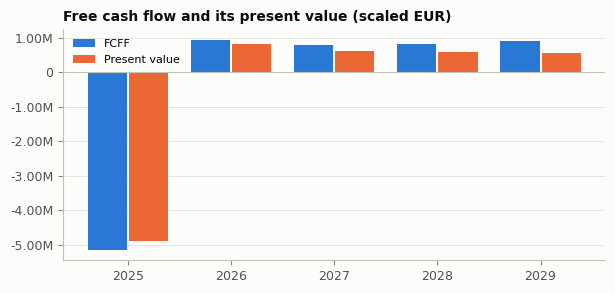

In [4]:
table(
    ["", *map(str, p.years)],
    [
        ["NOPAT (operating profit after tax)", *map(eur, pr.nopat[0])],
        ["− Increase in working capital", *map(eur, -pr.nwc_investment[0])],
        ["**Free cash flow**", *[f"**{eur(x)}**" for x in pr.fcf[0]]],
    ],
)
v = bc.valuation
show(plots.fcf_chart(p.years, pr.fcf[0], v.pv_by_year[0], "Free cash flow and its present value (scaled EUR)"))

## 4. The value

In [5]:
rows = [
    ["Present value of 2025-2029 cash flows", eur(v.pv_fcf[0])],
    ["Present value of the terminal value", eur(v.pv_terminal_value[0])],
    ["**Enterprise value**", f"**{eur(v.enterprise_value[0])}**"],
]
rows += [[f"{'+' if a >= 0 else '−'} {k.replace('_', ' ')}", eur(abs(a))] for k, a in cfg.bridge.items() if a]
rows += [["**Equity value**", f"**{eur(bc.equity_value)}**"]]
table(["Step", "Scaled EUR"], rows)
print(f"Terminal value as a share of enterprise value: {v.tv_share[0]:.1%}  (thesis: 155.7 %)")

| Step | Scaled EUR |
|---|---|
| Present value of 2025-2029 cash flows | -2,308,567 |
| Present value of the terminal value | 6,483,736 |
| **Enterprise value** | **4,175,169** |
| + cash and financial placements | 2,420,000 |
| + receivables from state funds | 10,000 |
| − tax liabilities | 290,000 |
| **Equity value** | **6,315,169** |

Terminal value as a share of enterprise value: 155.3%  (thesis: 155.7 %)


The terminal value is **more than 100 %** of the enterprise value, because the explicit years together are negative. Almost the whole value rests on the long-term steady state: the margin, the growth rate and the discount rate after 2029.

## 5. Sensitivity to the discount rate and long-term growth

Values are shown relative to the base case (1.00 = base).

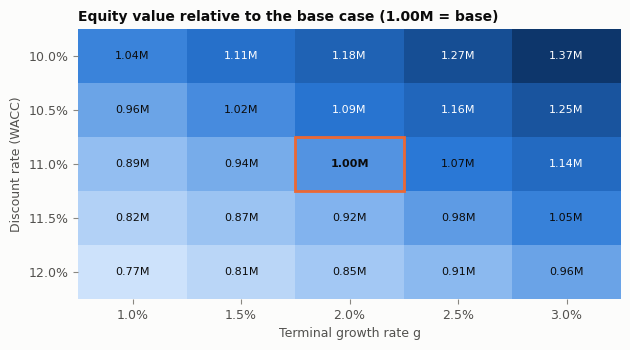

In [6]:
s = cfg.sensitivity
grid = dv.sensitivity_grid(cfg, s.wacc, s.terminal_growth)
show(
    plots.heatmap(
        grid / bc.equity_value * 1e6,
        s.wacc,
        s.terminal_growth,
        "Equity value relative to the base case (1.00M = base)",
        base=(w.wacc, cfg.terminal.growth),
    )
)

Here the long-term growth rate matters a lot, which is the opposite of the start-up. At an 11 % discount rate the distant future still carries weight. Each percentage point of g moves the value by roughly 11-14 %.

## 6. Monte Carlo simulation

Four inputs vary at random (thesis Table 15). The ranges are narrower than for the start-up, because the business is established:

| Input | How it varies |
|---|---|
| Revenue growth vs the plan | normal, ±2 percentage points every year |
| EBIT margin | shifted by a normal amount, ±0.3 percentage points |
| Discount rate | normal around 11 %, ±0.5 points |
| Long-term growth | triangular between 1.4 % and 2.6 % |

To match the thesis exactly, the simulation must continue the **same random number stream** as the start-up simulation. `reproduce()` runs both models in the thesis order.

| Statistic | Relative to base case | Thesis (Table 16) |
|---|---|---|
| Mean | 0.994 | 0.994 |
| Median | 0.998 | 0.998 |
| 5th percentile | 0.573 | 0.570 |
| 95th percentile | 1.398 | 1.400 |
| Coefficient of variation | 0.253 | 0.255 |
| Probability below the base case | 50.3% | 50.3 % |

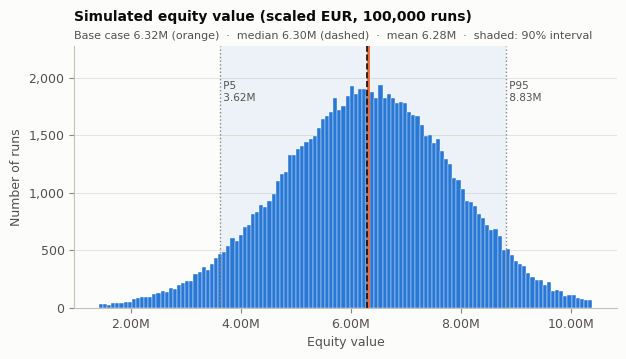

In [7]:
results = reproduce(EXAMPLES)
run = results["company_b"]
st, base = run.stats, run.base.equity_value
table(
    ["Statistic", "Relative to base case", "Thesis (Table 16)"],
    [
        ["Mean", f"{st['mean'] / base:.3f}", "0.994"],
        ["Median", f"{st['p50'] / base:.3f}", "0.998"],
        ["5th percentile", f"{st['p5'] / base:.3f}", "0.570"],
        ["95th percentile", f"{st['p95'] / base:.3f}", "1.400"],
        ["Coefficient of variation", f"{st['cv']:.3f}", "0.255"],
        ["Probability below the base case", f"{st['p_below_base']:.1%}", "50.3 %"],
    ],
)
show(plots.histogram(run.simulation.equity_value, base, "Simulated equity value (scaled EUR, 100,000 runs)"))

The distribution is roughly symmetric, and 90 % of outcomes lie between about **57 % and 140 % of the base case**. That is far narrower than the start-up's 21 % to 258 %.

## 7. What drives the value? And a surprise

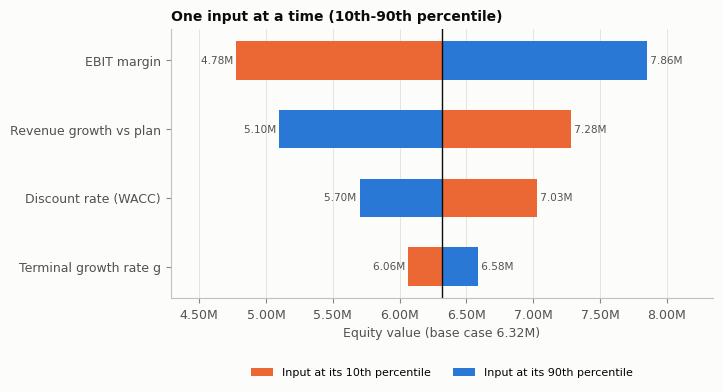

| Input | Rank correlation with value |
|---|---|
| EBIT margin | +0.75 |
| Revenue growth vs plan | -0.52 |
| Discount rate (WACC) | -0.31 |
| Terminal growth rate g | +0.12 |

In [8]:
show(plots.tornado_chart(run.tornado, base, "One input at a time (10th-90th percentile)"))
table(
    ["Input", "Rank correlation with value"],
    [[LABELS[k], f"{r:+.2f}"] for k, r in sorted(run.spearman.items(), key=lambda kv: -abs(kv[1]))],
)

The **EBIT margin** matters most: on revenue of this size, a fraction of a percentage point of margin is a lot of money every year, forever.

The surprise is that **faster revenue growth lowers the value** (correlation −0.52). Why? Each extra euro of sales ties up about 17-21 cents of working capital (stock and unpaid customer invoices), but it earns less than 2 cents of after-tax profit. The return on that extra capital is below the 11 % cost of capital, so growing faster destroys value. The cell below checks this directly:

In [9]:
for shift in (-0.02, 0.0, 0.02):
    val = dv.equity_value(cfg, revenue_growth_deviation=shift)[0]
    print(f"growth {shift:+.0%} per year vs plan  ->  value = {val / base:.3f} x base case")

growth -2% per year vs plan  ->  value = 1.123 x base case
growth +0% per year vs plan  ->  value = 1.000 x base case
growth +2% per year vs plan  ->  value = 0.854 x base case


## 8. The two companies side by side

Dividing every simulated value by its own base case puts both companies on one scale:

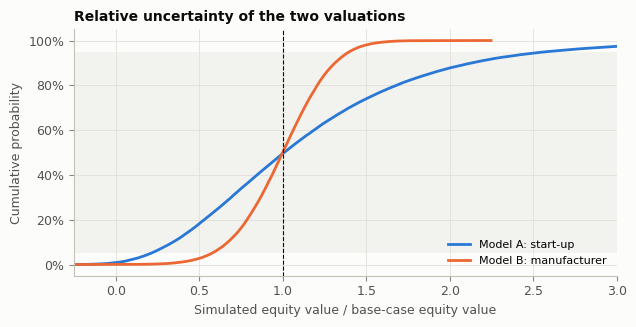

In [10]:
a = results["startup"]
show(
    plots.compare_cdf(
        {
            "Model A: start-up": (a.simulation.equity_value, a.base.equity_value),
            "Model B: manufacturer": (run.simulation.equity_value, base),
        }
    )
)

The steep orange curve means the manufacturer's value is concentrated close to its base case. The flat blue curve means the start-up's value could be almost anything from a fraction of its base case to several times it.

## Takeaways

* Both valuations use the same method. The difference in reliability comes from the **company**, not the technique.
* For an established firm, the critical judgements are the **long-term margin** and the **working capital** it needs. Neither shows up as a headline number.
* Growth is good only when the return on the capital it requires exceeds the cost of that capital.

To check every number against the thesis, run `python scripts/reproduce_thesis.py`.